# 02 · Exploración descriptiva del dataset (EA2)

**Proyecto:** Análisis Descriptivo de la Estancia Hospitalaria y Factores Operativos en Admisiones Médicas.

Este notebook **vuelve a descargar el dataset completo** desde Hugging Face con `HFDatasetLoader`, lo transforma en memoria con `src/data/transformations.py` (las mismas funciones del notebook 01) y realiza toda la exploración sobre ese DataFrame completo.

> **No se leen los CSV de `data/raw` ni `data/processed`**: están limitados a 100.000 filas y no contienen todos los registros.

Además genera automáticamente `reports/exploratory-analysis.txt` con los resultados calculados aquí.

## A. Contextualización de los datos

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "config.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

from src import config
from src.data.dataset_io import download_and_transform
from src.data.transformations import describe_log
from src.analysis import descriptive as ds
from src.utils.reporter import ExploratoryReport

raw, df, log, info = download_and_transform()   # descarga COMPLETA desde Hugging Face
print(f"Dataset: {info['dataset_id']} | configuración: {info['config']} | split: {info['split']}")
print(f"Filas descargadas: {len(raw):,} | filas tras transformar: {len(df):,} | {info['muestreo']}")

d:\Documents\Study\IUDigital\proyecto_integrado_3\healthcare-hospital-stay-analytics\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset: Nicolybgs/healthcare_data | configuración: default | split: train
Filas descargadas: 500,000 | filas tras transformar: 500,000 | dataset completo (sin muestreo)


**Qué dice la ficha** ([Hugging Face](https://huggingface.co/datasets/Nicolybgs/healthcare_data), consultada para este proyecto): una configuración (`default`), un split (`train`), ~500.000 filas, formato CSV. La ficha **no tiene dataset card**: no documenta la licencia, la procedencia, si los datos son reales o sintéticos, el periodo cubierto, ni el significado ni las unidades de las columnas. Todo ello queda **pendiente de verificar**.

**Unidad de análisis (inferida de la estructura, no documentada):** cada fila parece representar una admisión hospitalaria de un paciente (departamento, médico, tipo de admisión, severidad, depósito y días de estancia). `patientid` **no es único** (aparece repetido en varias filas), por lo que no equivale a un registro por paciente.

## B. Reconocimiento básico

### B.1 Primeros registros, dimensiones, columnas y tipos

In [2]:
display(df.head())
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
print("Columnas:", list(df.columns))
df.dtypes.astype(str).rename("tipo").to_frame()

,available_extra_rooms_in_hospital,department,ward_facility_code,doctor_name,staff_available,patientid,age,gender,type_of_admission,severity_of_illness,health_conditions,visitors_with_patient,insurance,admission_deposit,stay_in_days,staff_availability_group
0,4,gynecology,D,Dr Sophia,0,33070,41-50,Female,Trauma,Extreme,Diabetes,4,Yes,2966.408696,8,Bajo (0-3)
1,4,gynecology,B,Dr Sophia,2,34808,31-40,Female,Trauma,Minor,Heart disease,2,No,3554.835677,9,Bajo (0-3)
2,2,gynecology,B,Dr Sophia,8,44577,21-30,Female,Trauma,Extreme,Diabetes,2,Yes,5624.733654,7,Alto (7+)
3,4,gynecology,D,Dr Olivia,7,3695,31-40,Female,Urgent,Moderate,NaN,4,No,4814.149231,8,Alto (7+)
4,2,anesthesia,E,Dr Mark,10,108956,71-80,Male,Trauma,Moderate,Diabetes,2,No,5169.269637,34,Alto (7+)


Dimensiones: 500,000 filas x 16 columnas
Columnas: ['available_extra_rooms_in_hospital', 'department', 'ward_facility_code', 'doctor_name', 'staff_available', 'patientid', 'age', 'gender', 'type_of_admission', 'severity_of_illness', 'health_conditions', 'visitors_with_patient', 'insurance', 'admission_deposit', 'stay_in_days', 'staff_availability_group']


,tipo
available_extra_rooms_in_hospital,int64
department,category
ward_facility_code,category
doctor_name,category
staff_available,int64
patientid,int64
age,category
gender,category
type_of_admission,category
severity_of_illness,category


### B.2 Valores nulos y filas duplicadas

In [3]:
nulls = ds.null_table(df)
display(nulls)
n_dup = int(df.duplicated().sum())
print("Filas duplicadas (todas las columnas):", n_dup)
print("Valores de patientid repetidos:", int(df["patientid"].duplicated().sum()), "| patientid negativos:", int((df["patientid"] < 0).sum()))

,nulos,porcentaje
available_extra_rooms_in_hospital,0,0.00
department,0,0.00
ward_facility_code,0,0.00
doctor_name,0,0.00
staff_available,0,0.00
patientid,0,0.00
age,0,0.00
gender,0,0.00
type_of_admission,0,0.00
severity_of_illness,0,0.00


Filas duplicadas (todas las columnas): 0
Valores de patientid repetidos: 373601 | patientid negativos: 888


### B.3 Estadísticas descriptivas de variables numéricas

In [4]:
num_stats = ds.numeric_stats(df)
num_stats

,count,mean,std,min,25%,50%,75%,max,mediana
available_extra_rooms_in_hospital,500000.0,3.639,2.698,0.000,2.000,3.000,4.000,24.000,3.000
staff_available,500000.0,5.020,3.158,0.000,2.000,5.000,8.000,10.000,5.000
patientid,500000.0,63150.519,41689.480,-3269.000,25442.000,57864.000,103392.000,134400.000,57864.000
visitors_with_patient,500000.0,3.549,2.241,0.000,2.000,3.000,4.000,32.000,3.000
admission_deposit,500000.0,4722.316,1047.324,1654.005,4071.715,4627.004,5091.613,10104.726,4627.004
stay_in_days,500000.0,12.381,7.913,3.000,8.000,9.000,11.000,51.000,9.000


### B.4 Frecuencias de variables categóricas

In [5]:
cat_cols = ["department", "ward_facility_code", "doctor_name", "age", "gender", "type_of_admission",
            "severity_of_illness", "health_conditions", "insurance", "staff_availability_group"]
freqs = {c: ds.category_frequency(df, c) for c in cat_cols}
for c, t in freqs.items():
    print(f"\n{c}")
    display(t)


department


,registros,porcentaje
department,,
TB & Chest disease,22890,4.58
anesthesia,44179,8.84
gynecology,343478,68.70
radiotherapy,84315,16.86
surgery,5138,1.03



ward_facility_code


,registros,porcentaje
ward_facility_code,,
A,46551,9.31
B,103885,20.78
C,14597,2.92
D,119055,23.81
E,95374,19.07
F,120538,24.11



doctor_name


...

,registros,porcentaje
health_conditions,,
Asthama,65514,13.10
Diabetes,73644,14.73
Heart disease,35141,7.03
High Blood Pressure,79402,15.88
Other,94411,18.88
(nulo),151888,30.38



insurance


,registros,porcentaje
insurance,,
No,107040,21.41
Yes,392960,78.59



staff_availability_group


,registros,porcentaje
staff_availability_group,,
Bajo (0-3),180291,36.06
Medio (4-6),137125,27.42
Alto (7+),182584,36.52


## C. Exploración descriptiva orientada a la necesidad

Variables de interés: `stay_in_days` (duración de la estancia) y `admission_deposit` (depósito de admisión), comparadas según `department`, `severity_of_illness` y la disponibilidad de personal (`staff_available`, agrupada en `staff_availability_group`). Las tablas indican cantidad de registros, media, mediana, desviación estándar, mínimo y máximo.

> Son comparaciones **descriptivas**; las diferencias observadas no demuestran que una variable cause cambios en otra.

### C.1 Distribución de la estancia y del depósito

Valores atípicos por regla 1.5xIQR (se conservan, no se eliminan): {'stay_in_days': 111707, 'admission_deposit': 41677}


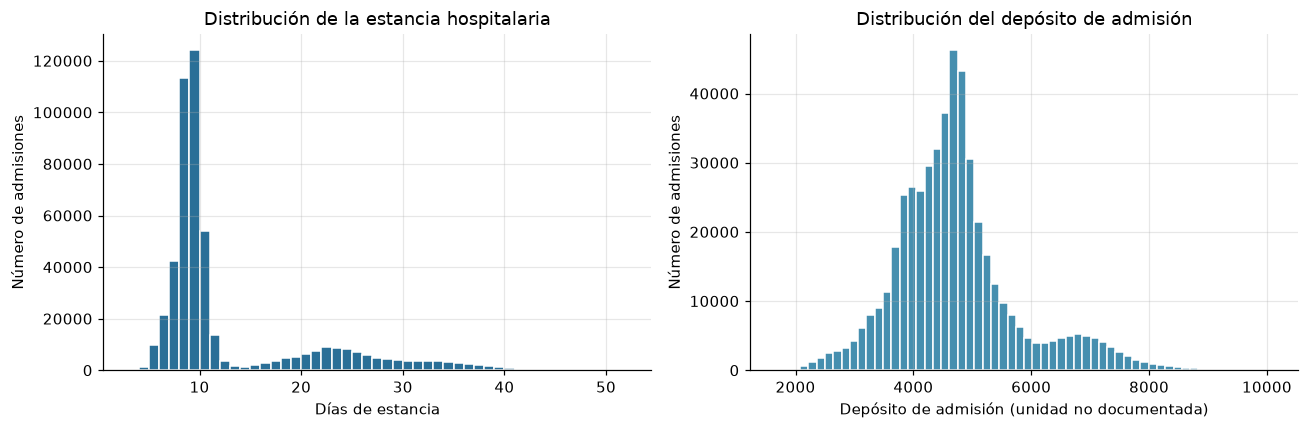

In [6]:
targets = ["stay_in_days", "admission_deposit"]
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); i = q3 - q1
    return int(((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum())
outliers = {c: iqr_outliers(df[c]) for c in targets}
print("Valores atípicos por regla 1.5xIQR (se conservan, no se eliminan):", outliers)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["stay_in_days"], bins=range(3, 53), color="#2a6f97", edgecolor="white")
axes[0].set(title="Distribución de la estancia hospitalaria", xlabel="Días de estancia", ylabel="Número de admisiones")
axes[1].hist(df["admission_deposit"], bins=60, color="#468faf", edgecolor="white")
axes[1].set(title="Distribución del depósito de admisión", xlabel="Depósito de admisión (unidad no documentada)", ylabel="Número de admisiones")
plt.tight_layout(); plt.show()

### C.2 Por departamento

,registros,stay_in_days_mean,stay_in_days_median,stay_in_days_std,stay_in_days_min,stay_in_days_max,admission_deposit_mean,admission_deposit_median,admission_deposit_std,admission_deposit_min,admission_deposit_max
department,,,,,,,,,,,
TB & Chest disease,22890,21.14,24.0,8.57,4,41,4798.82,4682.72,1070.73,1818.93,9473.51
anesthesia,44179,27.54,30.0,8.04,9,51,4825.66,4702.52,1070.29,1715.80,10104.73
gynecology,343478,8.64,9.0,1.06,3,14,4692.08,4599.54,1038.73,1654.01,9899.19
radiotherapy,84315,16.20,20.0,8.47,3,33,4768.67,4675.91,1065.05,1889.78,9692.65
surgery,5138,30.74,35.0,11.24,8,51,4753.70,4718.34,909.97,2171.49,9585.47


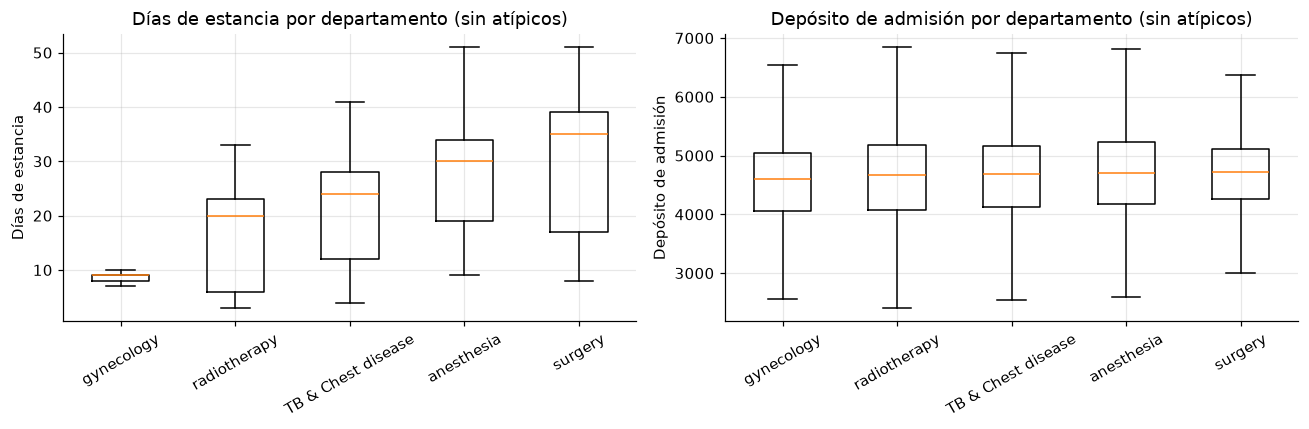

In [7]:
by_dept = ds.group_summary(df, "department", targets)
display(by_dept)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t, lab in zip(axes, targets, ["Días de estancia", "Depósito de admisión"]):
    order = by_dept.sort_values(f"{t}_median").index
    ax.boxplot([df.loc[df["department"] == d, t] for d in order], tick_labels=order, showfliers=False)
    ax.set(title=f"{lab} por departamento (sin atípicos)", ylabel=lab); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### C.3 Por severidad de la enfermedad

,registros,stay_in_days_mean,stay_in_days_median,stay_in_days_std,stay_in_days_min,stay_in_days_max,admission_deposit_mean,admission_deposit_median,admission_deposit_std,admission_deposit_min,admission_deposit_max
severity_of_illness,,,,,,,,,,,
Minor,131537,11.45,9.0,6.97,3,51,4749.10,4636.65,1058.42,1654.01,9813.47
Moderate,280197,12.72,9.0,8.18,3,51,4718.71,4621.39,1049.48,1715.80,10104.73
Extreme,88266,12.69,9.0,8.25,3,50,4693.85,4630.06,1022.66,1744.90,9897.66


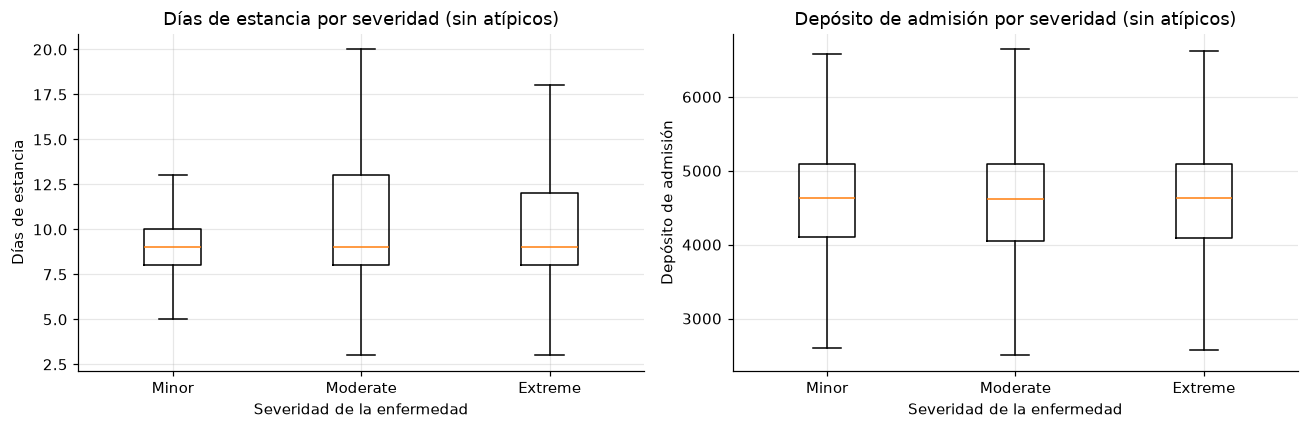

In [8]:
by_sev = ds.group_summary(df, "severity_of_illness", targets)
display(by_sev)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, t, lab in zip(axes, targets, ["Días de estancia", "Depósito de admisión"]):
    ax.boxplot([df.loc[df["severity_of_illness"] == s, t] for s in by_sev.index], tick_labels=by_sev.index, showfliers=False)
    ax.set(title=f"{lab} por severidad (sin atípicos)", xlabel="Severidad de la enfermedad", ylabel=lab)
plt.tight_layout(); plt.show()

### C.4 Por disponibilidad de personal

,registros,stay_in_days_mean,stay_in_days_median,stay_in_days_std,stay_in_days_min,stay_in_days_max,admission_deposit_mean,admission_deposit_median,admission_deposit_std,admission_deposit_min,admission_deposit_max
staff_availability_group,,,,,,,,,,,
Bajo (0-3),180291,12.26,9.0,7.74,3,51,4722.89,4625.05,1048.70,1654.01,9872.65
Medio (4-6),137125,12.59,9.0,8.18,3,51,4718.34,4626.81,1043.22,1690.92,9657.61
Alto (7+),182584,12.35,9.0,7.88,3,50,4724.74,4628.78,1049.04,1725.69,10104.73


,registros,stay_in_days_mean,stay_in_days_median,stay_in_days_std,stay_in_days_min,stay_in_days_max,admission_deposit_mean,admission_deposit_median,admission_deposit_std,admission_deposit_min,admission_deposit_max
staff_available,,,,,,,,,,,
0,45032,12.19,9.0,7.66,4,48,4718.53,4622.30,1048.40,1789.17,9463.34
1,44931,12.20,9.0,7.67,3,46,4723.84,4628.14,1047.66,1825.58,9813.47
2,44670,12.21,9.0,7.66,3,47,4728.02,4626.35,1045.27,1654.01,9872.65
3,45658,12.43,9.0,7.97,3,51,4721.24,4623.32,1053.36,1695.30,9815.57
4,45290,12.37,9.0,7.90,3,49,4717.85,4622.54,1043.24,1750.22,9465.65
5,45215,12.45,9.0,7.94,3,51,4720.10,4629.46,1044.21,1690.92,9657.61
6,46620,12.94,9.0,8.65,3,50,4717.11,4627.98,1042.26,1805.16,9552.02
7,45703,12.39,9.0,7.92,3,48,4726.41,4631.09,1047.31,1747.38,10104.73
8,45583,12.35,9.0,7.90,3,50,4723.50,4630.19,1048.52,1725.69,9611.32


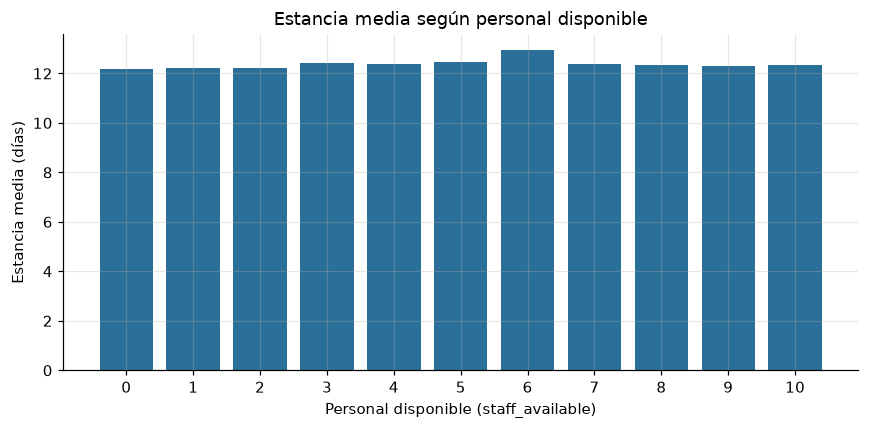

In [9]:
by_staff_group = ds.group_summary(df, "staff_availability_group", targets)
display(by_staff_group)
by_staff = ds.group_summary(df, "staff_available", targets)
display(by_staff)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(by_staff.index.astype(str), by_staff["stay_in_days_mean"], color="#2a6f97")
ax.set(title="Estancia media según personal disponible", xlabel="Personal disponible (staff_available)", ylabel="Estancia media (días)")
plt.tight_layout(); plt.show()

### C.5 Cruce departamento × severidad y otras variables

In [10]:
cross_median = df.pivot_table(index="department", columns="severity_of_illness", values="stay_in_days", aggfunc="median", observed=True)
cross_count = pd.crosstab(df["department"], df["severity_of_illness"])
print("Mediana de estancia (días) por departamento y severidad"); display(cross_median)
print("Registros por departamento y severidad"); display(cross_count)

other_groups = {c: ds.group_summary(df, c, targets) for c in ["type_of_admission", "insurance", "ward_facility_code", "health_conditions", "age", "gender"]}
for c, t in other_groups.items():
    print(f"\n{c}"); display(t)

corr = df[["stay_in_days", "admission_deposit", "staff_available", "available_extra_rooms_in_hospital", "visitors_with_patient"]].corr(method="spearman").round(3)
print("\nCorrelación de Spearman (asociación, no causalidad)"); display(corr)

Mediana de estancia (días) por departamento y severidad


severity_of_illness,Minor,Moderate,Extreme
department,,,
TB & Chest disease,24.0,25.0,24.0
anesthesia,29.0,30.0,30.0
gynecology,9.0,9.0,9.0
radiotherapy,20.0,21.0,20.0
surgery,33.0,35.0,34.0


Registros por departamento y severidad


severity_of_illness,Minor,Moderate,Extreme
department,,,
TB & Chest disease,5505,13040,4345
anesthesia,9170,26487,8522
gynecology,98393,185472,59613
radiotherapy,17961,52271,14083
surgery,508,2927,1703



type_of_admission


...

,registros,stay_in_days_mean,stay_in_days_median,stay_in_days_std,stay_in_days_min,stay_in_days_max,admission_deposit_mean,admission_deposit_median,admission_deposit_std,admission_deposit_min,admission_deposit_max
age,,,,,,,,,,,
0-10,3368,27.25,27.0,5.61,9,48,4940.73,4759.92,1107.70,2067.25,9692.65
11-20,46536,8.69,9.0,1.07,3,13,4746.15,4643.07,1057.74,1654.01,9611.32
21-30,159793,10.72,9.0,6.14,4,49,4747.30,4640.12,1057.63,1695.30,10104.73
31-40,133373,8.94,9.0,2.98,3,26,4656.65,4565.09,1032.15,1725.69,9899.19
41-50,80406,9.04,9.0,2.93,3,25,4654.69,4584.61,1019.22,1690.92,9897.66
51-60,21718,27.47,26.0,5.93,9,50,4812.71,4710.74,1090.64,1988.49,9657.61
61-70,26556,27.13,26.0,5.92,9,51,4825.78,4720.29,1035.21,1715.80,9563.40
71-80,18703,26.36,25.0,5.81,9,50,4864.06,4754.35,1036.24,2046.63,9203.10
81-90,8181,26.28,24.0,6.18,12,49,4814.38,4695.89,1079.28,2032.72,9388.93



gender


,registros,stay_in_days_mean,stay_in_days_median,stay_in_days_std,stay_in_days_min,stay_in_days_max,admission_deposit_mean,admission_deposit_median,admission_deposit_std,admission_deposit_min,admission_deposit_max
gender,,,,,,,,,,,
Female,370810,9.52,9.0,4.28,3,50,4698.60,4605.19,1040.24,1654.01,10104.73
Male,103480,20.59,22.0,9.95,3,51,4787.33,4686.33,1062.28,1715.80,9692.65
Other,25710,20.53,22.0,9.95,3,51,4802.75,4694.24,1073.12,1799.69,9510.95



Correlación de Spearman (asociación, no causalidad)


,stay_in_days,admission_deposit,staff_available,available_extra_rooms_in_hospital,visitors_with_patient
stay_in_days,1.000,0.014,0.005,-0.070,-0.045
admission_deposit,0.014,1.000,0.001,-0.129,-0.151
staff_available,0.005,0.001,1.000,-0.002,-0.001
available_extra_rooms_in_hospital,-0.070,-0.129,-0.002,1.000,0.178
visitors_with_patient,-0.045,-0.151,-0.001,0.178,1.000


## D. Interpretación

*(Cifras tomadas de las tablas de la sección C, calculadas sobre las 500.000 filas.)*

**Observaciones estadísticas**

* **Departamento:** es la variable que más separa la estancia. Mediana (media) en días: ginecología 9 (8,64; desviación 1,06), radioterapia 20 (16,20), TB & Chest disease 24 (21,14), anestesia 30 (27,54) y cirugía 35 (30,74). Ginecología concentra 343.478 de las admisiones. El depósito medio varía poco entre departamentos (de 4.692 en ginecología a 4.826 en anestesia).
* **Severidad:** la mediana de estancia es 9 días en las tres categorías; la media es 11,45 (Minor), 12,72 (Moderate) y 12,69 (Extreme), diferencias pequeñas. El depósito medio baja ligeramente de Minor (4.749) a Extreme (4.694), también una diferencia pequeña. Dentro de cada departamento la mediana de estancia casi no cambia entre severidades (p. ej. ginecología 9/9/9).
* **Personal disponible:** las medias de estancia por grupo son 12,26 (Bajo), 12,59 (Medio) y 12,35 (Alto), y el depósito medio 4.723, 4.718 y 4.725. La correlación de Spearman de `staff_available` con la estancia (0,005) y con el depósito (0,001) es prácticamente nula: en este dataset no se observa un patrón relacionado con el personal disponible.
* **Otras variables:** la estancia tiene un comportamiento claramente distinto según la sala (`ward_facility_code`: A, C y E con medias de 19,7 a 22,5 días; B, D y F con 8,6 a 8,7), la edad (0-10 y 51 o más con medias de 26 a 28 días; 11-20, 31-40 y 41-50 con 8,7 a 9,0) y el género (Female 9,52 frente a Male 20,59 y Other 20,53). El depósito se asocia débilmente y de forma negativa con las habitaciones extra disponibles (ρ = -0,129) y con los visitantes (ρ = -0,151).

**Hipótesis (no verificadas)**

* Las diferencias de estancia por sala, edad y género podrían estar ligadas entre sí y con el departamento (por ejemplo, por cómo se distribuyen los pacientes entre servicios); este análisis no lo separa y no permite afirmarlo.
* La falta de relación aparente con el personal disponible puede deberse a cómo se registró esa variable (su definición no está documentada) y no a que el personal no importe.

**Limitaciones**

* La ficha no documenta licencia, procedencia, si los datos son reales o sintéticos, periodo ni unidades (p. ej., la moneda del depósito). Los resultados describen este conjunto de registros y no se pueden generalizar a otros hospitales.
* Son comparaciones descriptivas: no demuestran causalidad.
* `health_conditions` tiene 151.888 nulos (30,38 %) sin significado documentado; `patientid` se repite y tiene valores negativos, por lo que no equivale a un paciente único.
* El depósito de admisión no es necesariamente el costo total del tratamiento.
* La agrupación del personal (0-3, 4-6, 7+) es una convención del proyecto.


## E. Reporte automático `reports/exploratory-analysis.txt`
Se compone con las mismas tablas calculadas arriba (sin valores copiados a mano), en UTF-8, regenerándose en cada ejecución.

In [11]:
rep = ExploratoryReport()
rep.add_section("IDENTIFICACIÓN DEL DATASET", [
    f"Dataset: {info['dataset_id']}  ({config.DATASET_URL})",
    f"Configuración: {info['config']} | Split: {info['split']}",
    f"Carga: {info['muestreo']} (el análisis NO usa los CSV de data/, que están limitados a {config.CSV_MAX_ROWS} filas)",
    f"Filas analizadas: {len(df)} | Columnas: {df.shape[1]}",
    "Ficha de Hugging Face: sin dataset card; licencia, procedencia, carácter sintético/real y periodo NO documentados.",
])
rep.add_section("TRANSFORMACIONES APLICADAS (en memoria)", describe_log(log))
rep.add_section("COLUMNAS Y TIPOS", [f"- {c}: {t}" for c, t in df.dtypes.astype(str).items()])
rep.add_section("VALORES NULOS (cantidad y porcentaje) Y DUPLICADOS", [nulls.to_string(), "", f"Filas duplicadas: {n_dup}"])
rep.add_section("ESTADÍSTICAS DESCRIPTIVAS NUMÉRICAS", num_stats)
for c, t in freqs.items():
    rep.add_section(f"FRECUENCIAS: {c}", t)
rep.add_section("ESTANCIA Y DEPÓSITO: DISTRIBUCIÓN GENERAL", [f"Valores atípicos (regla 1.5xIQR, conservados): {outliers}"])
rep.add_section("COMPARACIÓN POR DEPARTAMENTO", by_dept)
rep.add_section("COMPARACIÓN POR SEVERIDAD DE LA ENFERMEDAD", by_sev)
rep.add_section("COMPARACIÓN POR GRUPO DE DISPONIBILIDAD DE PERSONAL", by_staff_group)
rep.add_section("COMPARACIÓN POR PERSONAL DISPONIBLE (0-10)", by_staff)
rep.add_section("MEDIANA DE ESTANCIA: DEPARTAMENTO x SEVERIDAD", [cross_median.to_string(), "", "Registros:", cross_count.to_string()])
for c, t in other_groups.items():
    rep.add_section(f"COMPARACIÓN POR {c.upper()}", t)
rep.add_section("CORRELACIÓN DE SPEARMAN (asociación, no causalidad)", corr)
warn = []
if nulls.loc["health_conditions", "nulos"] > 0:
    warn.append(f"- health_conditions tiene {int(nulls.loc['health_conditions', 'nulos'])} nulos ({nulls.loc['health_conditions', 'porcentaje']} %); la ficha no explica su significado: se conservan como nulos, no se imputan.")
warn.append(f"- patientid se repite en {int(df['patientid'].duplicated().sum())} filas y tiene {int((df['patientid'] < 0).sum())} valores negativos; no se usa como identificador único.")
warn.append("- Categoría 'Asthama' se conserva tal como figura en la fuente (posible error ortográfico).")
rep.add_section("ADVERTENCIAS DE CALIDAD", warn)
rep.add_section("LIMITACIONES", [
    "- Análisis descriptivo: las diferencias entre grupos NO implican causalidad.",
    "- La ficha no documenta periodo, población, procedencia, licencia ni significado/unidades de las variables (p. ej., moneda de admission_deposit).",
    "- El depósito de admisión no necesariamente representa el costo total del tratamiento.",
    "- Los umbrales de staff_availability_group son una convención del proyecto.",
    "- No se puede extrapolar a otros hospitales.",
])
path = rep.save(config.EXPLORATORY_TXT)
txt = path.read_text(encoding="utf-8")
assert f"Filas analizadas: {len(df)}" in txt
print("Generado:", path.relative_to(ROOT).as_posix(), f"({len(txt.splitlines())} líneas)")
print(txt[:3000], "\n[...]")

Generado: reports/exploratory-analysis.txt (319 líneas)
REPORTE DE ANÁLISIS EXPLORATORIO
Fecha de generación: 2026-10-25 17:26:54 UTC-0500

1. IDENTIFICACIÓN DEL DATASET
----------------------------------------------------------------------
Dataset: Nicolybgs/healthcare_data  (https://huggingface.co/datasets/Nicolybgs/healthcare_data)
Configuración: default | Split: train
Carga: dataset completo (sin muestreo) (el análisis NO usa los CSV de data/, que están limitados a 100000 filas)
Filas analizadas: 500000 | Columnas: 16
Ficha de Hugging Face: sin dataset card; licencia, procedencia, carácter sintético/real y periodo NO documentados.

2. TRANSFORMACIONES APLICADAS (en memoria)
----------------------------------------------------------------------
strip_text_values: Eliminación de espacios iniciales/finales en columnas de texto. Filas 500000 -> 500000; columnas 15 -> 15.
convert_numeric_types: Conversión validada a tipos numéricos (pd.to_numeric); valores no convertibles se reportan, n